# CNN FC128 và MLP260 — augmentation, seed 42

So sánh 4 trường hợp: hai mạng × không/có augmentation. Cùng split, thứ tự batch, SGD, learning rate và số epoch. Chọn checkpoint bằng validation CE, không chọn theo test. Chỉ chạy một seed; không đánh giá độ biến động giữa các lần huấn luyện.

## 1. Dữ liệu và cấu hình

Loader trả về 4 giá trị, ảnh đã chia 255. Chia stratify 50.000 train / 10.000 validation, test giữ riêng. Seed 42 cố định cả split, khởi tạo và thứ tự batch. Mặc định 15 epoch, batch 256; chạy CPU hoặc GPU. Cấu hình chung không đảm bảo mỗi kiến trúc đạt tối ưu riêng.

In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
from src.data import load_prepared_mnist
OUTPUT = ROOT/'results'/'cnn_mlp_augmentation'
OUTPUT.mkdir(parents=True,exist_ok=True)
SEED = 42
EPOCHS, BATCH_SIZE, LR, MOMENTUM = 15, 256, 0.01, 0.9
MAX_ROTATION, MAX_SHIFT, NOISE_STD = 30.0, 4.0, 0.1
MODES, CLASSES = ['none','all'], np.arange(10)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

X,y,X_test,y_test = load_prepared_mnist()
X,y = np.asarray(X,np.float32),np.asarray(y,dtype=int)
X_test,y_test = np.asarray(X_test,np.float32),np.asarray(y_test,dtype=int)
tr,va = train_test_split(np.arange(len(y)),test_size=10000,stratify=y,random_state=SEED)
data = {'Train':(X[tr],y[tr]),'Validation':(X[va],y[va]),'Test':(X_test,y_test)}
datasets = {split:TensorDataset(torch.from_numpy(a.reshape(-1,1,28,28)),torch.as_tensor(b,dtype=torch.long))
            for split,(a,b) in data.items()}
loaders = {split:DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False) for split,ds in datasets.items()}
print('Device:',DEVICE,'| 4 trường hợp, seed:',SEED)
for split,ds in datasets.items():print(split,len(ds))
del X

Device: cpu | 4 trường hợp, seed: 42
Train 50000
Validation 10000
Test 10000


## 2. Hai mô hình và ảnh tăng cường

MLP: 784–260–10, CNN: Conv16–Pool–Conv32–Pool–FC128–10. Hai mạng có lần lượt 206.710 và 206.922 tham số; số phép tính không bằng nhau.

Chỉ ảnh train được xoay ±30°, dịch ngang/dọc ±4 pixel và thêm nhiễu Gaussian σ=0,1, chặn pixel [0,1]. Biến đổi dùng phép affine/bilinear của PyTorch, nền ngoài ảnh bằng 0. Ảnh có thể mất nét hoặc khó nhận khi biến đổi mạnh; xem ví dụ dưới đây. Validation/test chính giữ sạch.

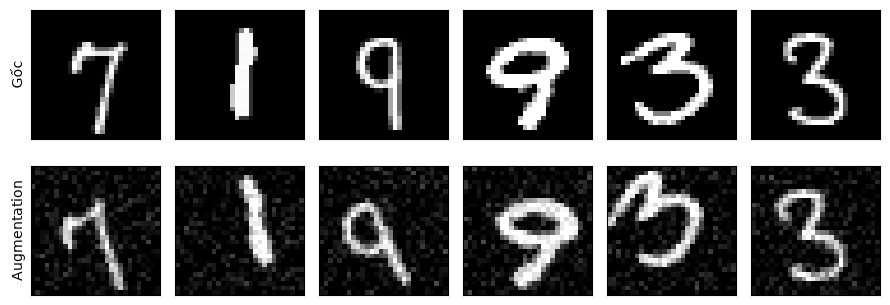

,model,parameters
0,MLP260,206710
1,CNN_FC128,206922


In [2]:
def make_mlp():
    return nn.Sequential(nn.Flatten(),nn.Linear(784,260),nn.ReLU(),nn.Linear(260,10))
def make_cnn():
    return nn.Sequential(nn.Conv2d(1,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
        nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
        nn.Flatten(),nn.Linear(32*7*7,128),nn.ReLU(),nn.Linear(128,10))
makers={'MLP260':make_mlp,'CNN_FC128':make_cnn}
parameters={n:sum(p.numel() for p in make().parameters()) for n,make in makers.items()}

def apply_affine(images,angle,dx,dy):
    n,_,h,w=images.shape
    c,t=torch.cos(angle*torch.pi/180),torch.sin(angle*torch.pi/180)
    dx,dy=dx*2/w,dy*2/h
    theta=torch.zeros(n,2,3,dtype=images.dtype)
    theta[:,0,0],theta[:,0,1]=c,t
    theta[:,1,0],theta[:,1,1]=-t,c
    theta[:,0,2],theta[:,1,2]=-c*dx-t*dy,t*dx-c*dy
    grid=F.affine_grid(theta,images.size(),align_corners=False)
    return F.grid_sample(images,grid,mode='bilinear',padding_mode='zeros',align_corners=False)


def augment_batch(images,generator):
    n=len(images)
    angle=(torch.rand(n,generator=generator)*2-1)*MAX_ROTATION
    dx=(torch.rand(n,generator=generator)*2-1)*MAX_SHIFT
    dy=(torch.rand(n,generator=generator)*2-1)*MAX_SHIFT
    changed=apply_affine(images,angle,dx,dy)
    noise=torch.randn(images.shape,generator=generator,dtype=images.dtype)*NOISE_STD
    return (changed+noise).clamp(0,1)

example=datasets['Train'].tensors[0][:6]
changed=augment_batch(example,torch.Generator().manual_seed(SEED+1000))
fig,axes=plt.subplots(2,6,figsize=(9,3.5))
for j in range(6):
    axes[0,j].imshow(example[j,0],cmap='gray',vmin=0,vmax=1)
    axes[1,j].imshow(changed[j,0],cmap='gray',vmin=0,vmax=1)
    for ax in axes[:,j]:ax.set_xticks([]);ax.set_yticks([])
axes[0,0].set_ylabel('Gốc');axes[1,0].set_ylabel('Augmentation')
fig.tight_layout();fig.savefig(OUTPUT/'augmentation_examples.png',dpi=300);plt.show()
display(pd.DataFrame({'model':list(parameters),'parameters':list(parameters.values())}))

## 3. Huấn luyện chung

Trong mỗi kiến trúc, baseline và augmentation có cùng khởi tạo; hai mạng dùng cùng thứ tự batch và biến thể ảnh. Chạy đủ số epoch, giữ validation CE thấp nhất. Train/validation đều đo trên ảnh sạch cuối epoch. Thời gian gồm augmentation, cập nhật và đánh giá; chưa phải benchmark độc lập.

In [3]:
def synchronize():
    if DEVICE.type=='cuda':torch.cuda.synchronize()

@torch.no_grad()
def evaluate(model,loader):
    model.eval();loss_sum,count,predictions=0.,0,[]
    for xb,yb in loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        logits=model(xb)
        loss_sum+=F.cross_entropy(logits,yb,reduction='sum').item();count+=len(yb)
        predictions.append(logits.argmax(1).cpu().numpy())
    pred=np.concatenate(predictions)
    return loss_sum/count,pred

def train_one(name,mode):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    model=makers[name]().to(DEVICE)
    loader=DataLoader(datasets['Train'],batch_size=BATCH_SIZE,shuffle=True,
        generator=torch.Generator().manual_seed(SEED))
    aug_generator=torch.Generator().manual_seed(SEED+1000)
    optimizer=torch.optim.SGD(model.parameters(),lr=LR,momentum=MOMENTUM)
    rows,best_loss,best_epoch,best_state=[],np.inf,None,None
    synchronize();start=time.perf_counter()
    with torch.enable_grad():
        for epoch in range(1,EPOCHS+1):
            model.train()
            for xb,yb in loader:
                if mode=='all':xb=augment_batch(xb,aug_generator)
                xb,yb=xb.to(DEVICE),yb.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss=F.cross_entropy(model(xb),yb);loss.backward();optimizer.step()
            tl,tp=evaluate(model,loaders['Train']);vl,vp=evaluate(model,loaders['Validation'])
            rows.append(dict(epoch=epoch,train_loss=tl,val_loss=vl,
                train_accuracy=accuracy_score(data['Train'][1],tp),val_accuracy=accuracy_score(data['Validation'][1],vp)))
            if vl<best_loss:
                best_loss,best_epoch=vl,epoch
                best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            print(f'{name} {mode} epoch={epoch:02d} val={rows[-1]["val_accuracy"]:.4f}',flush=True)
    synchronize()
    return dict(state_dict=best_state,history=rows,best_epoch=best_epoch,
        fit_seconds=time.perf_counter()-start)



fitted, histories, run_rows = {}, {}, []
for name,make in makers.items():
    for mode in MODES:
        checkpoint=train_one(name,mode)
        model=make().to(DEVICE)
        model.load_state_dict(checkpoint['state_dict']);model.eval()
        fitted[name,mode]=model
        histories[name,mode]=pd.DataFrame(checkpoint['history'])
        run_rows.append(dict(model=name,mode=mode,best_epoch=checkpoint['best_epoch'],fit_seconds=checkpoint['fit_seconds']))
        checkpoint.update(model=name,mode=mode,seed=SEED,classes=CLASSES.tolist(),
            preprocessing='loader pixel /255; N,1,28,28',
            augmentation=dict(rotation=MAX_ROTATION,shift=MAX_SHIFT,noise_std=NOISE_STD),
            epochs=EPOCHS,batch_size=BATCH_SIZE,learning_rate=LR,momentum=MOMENTUM)
        torch.save(checkpoint,OUTPUT/f'{name}_{mode}.pt')
runs=pd.DataFrame(run_rows)

MLP260 none epoch=01 val=0.8827
MLP260 none epoch=02 val=0.9043
MLP260 none epoch=03 val=0.9143
MLP260 none epoch=04 val=0.9206
MLP260 none epoch=05 val=0.9295
MLP260 none epoch=06 val=0.9314
MLP260 none epoch=07 val=0.9358
MLP260 none epoch=08 val=0.9399
MLP260 none epoch=09 val=0.9441
MLP260 none epoch=10 val=0.9478
MLP260 none epoch=11 val=0.9486
MLP260 none epoch=12 val=0.9520
MLP260 none epoch=13 val=0.9539
MLP260 none epoch=14 val=0.9568
MLP260 none epoch=15 val=0.9575
MLP260 all epoch=01 val=0.6451
MLP260 all epoch=02 val=0.6759
MLP260 all epoch=03 val=0.7546
MLP260 all epoch=04 val=0.7977
MLP260 all epoch=05 val=0.8230
MLP260 all epoch=06 val=0.8401
MLP260 all epoch=07 val=0.8364
MLP260 all epoch=08 val=0.8562
MLP260 all epoch=09 val=0.8662
MLP260 all epoch=10 val=0.8606
MLP260 all epoch=11 val=0.8714
MLP260 all epoch=12 val=0.8780
MLP260 all epoch=13 val=0.8690
MLP260 all epoch=14 val=0.8749
MLP260 all epoch=15 val=0.8751
CNN_FC128 none epoch=01 val=0.9031
CNN_FC128 none epoch

## 4. Kết quả sạch và đường học

Bảng chính gồm accuracy train/validation/test, F1 test, gap train−validation và thời gian. Bảng tác động lấy augmentation trừ baseline trong cùng mạng; đếm cả lỗi sửa đúng và lỗi tạo thêm trên test sạch.

Gap nhỏ hơn chưa chứng minh tốt hơn nếu validation giảm. Các đường train/validation dùng trọng số cuối epoch; không thay cấu hình sau khi xem test.

,model,mode,Test,Train,Validation,f1_macro,errors,best_epoch,fit_seconds,gap_pp
0,CNN_FC128,all,0.9824,0.98102,0.9810,0.98233,176,14,110.38541,0.002
1,CNN_FC128,none,0.9857,0.99120,0.9838,0.98560,143,13,120.84457,0.740
2,MLP260,all,0.8763,0.87400,0.8780,0.87328,1237,12,34.85817,-0.400
3,MLP260,none,0.9598,0.96430,0.9575,0.95943,402,15,18.30743,0.680


Tác động augmentation trên test sạch:


,model,accuracy_gain_pp,f1_gain_pp,corrected,introduced,extra_fit_seconds
0,MLP260,-8.35,-8.6148,142,977,16.5507
1,CNN_FC128,-0.33,-0.3274,75,108,-10.4592


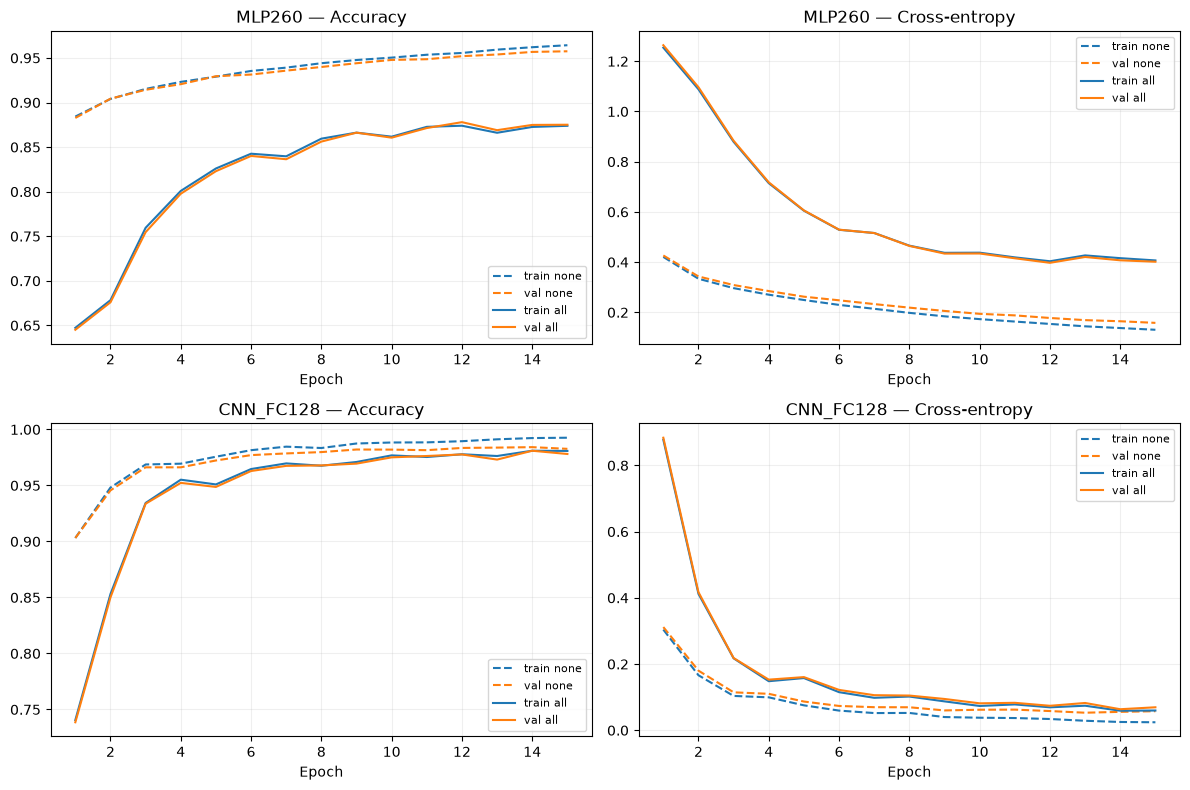

In [4]:
rows,predictions=[],{}
for (name,mode),model in fitted.items():
    for split,loader in loaders.items():
        loss,pred=evaluate(model,loader);target=data[split][1]
        precision,recall,f1,_=precision_recall_fscore_support(target,pred,labels=CLASSES,average='macro',zero_division=0)
        predictions[name,mode,split]=pred
        rows.append(dict(model=name,mode=mode,split=split,loss=loss,accuracy=accuracy_score(target,pred),
            precision_macro=precision,recall_macro=recall,f1_macro=f1,errors=int((pred!=target).sum())))
metrics=pd.DataFrame(rows)
comparison=metrics.pivot(index=['model','mode'],columns='split',values='accuracy').reset_index()
comparison.columns.name=None
comparison=comparison.merge(metrics[metrics.split=='Test'][['model','mode','f1_macro','errors']],on=['model','mode'])
comparison=comparison.merge(runs,on=['model','mode'])
comparison['gap_pp']=100*(comparison.Train-comparison.Validation)
display(comparison.round(5))

effect_rows=[]
for name in makers:
    table=comparison[comparison.model==name].set_index('mode')
    baseline,aug=table.loc['none'],table.loc['all']
    right0=predictions[name,'none','Test']==y_test
    right1=predictions[name,'all','Test']==y_test
    effect_rows.append(dict(model=name,accuracy_gain_pp=100*(aug.Test-baseline.Test),
        f1_gain_pp=100*(aug.f1_macro-baseline.f1_macro),corrected=int((~right0&right1).sum()),
        introduced=int((right0&~right1).sum()),extra_fit_seconds=aug.fit_seconds-baseline.fit_seconds))
effects=pd.DataFrame(effect_rows)
print('Tác động augmentation trên test sạch:');display(effects.round(4))

fig,axes=plt.subplots(2,2,figsize=(12,8))
for row,name in enumerate(makers):
    for mode in MODES:
        h=histories[name,mode]
        for col,metric in enumerate(['accuracy','loss']):
            for split,color in [('train','tab:blue'),('val','tab:orange')]:
                axes[row,col].plot(h.epoch,h[f'{split}_{metric}'],color=color,
                    linestyle='-' if mode=='all' else '--',label=f'{split} {mode}')
    for col in range(2):
        axes[row,col].set(xlabel='Epoch',title=name+' — '+['Accuracy','Cross-entropy'][col])
        axes[row,col].legend(fontsize=8);axes[row,col].grid(alpha=.2)
fig.tight_layout();fig.savefig(OUTPUT/'learning_curves.png',dpi=300);plt.show()

## 5. Độ bền với xoay và dịch
Tạo bản sao test bị dịch 0–4 pixel hoặc xoay 0–30°. Mỗi model nhận đúng cùng ảnh biến đổi, hướng dịch/dấu xoay cố định theo ảnh.

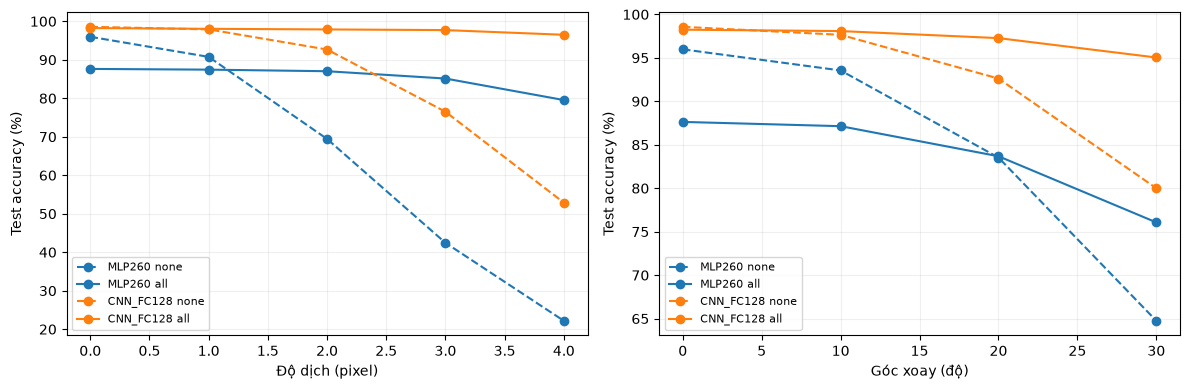

In [5]:
SHIFTS,ROTATIONS=[0,1,2,3,4],[0,10,20,30]
test_images,test_labels=datasets['Test'].tensors
rng=np.random.default_rng(SEED+5000)
directions=rng.integers(0,4,len(test_labels))
signs=torch.from_numpy(rng.choice([-1.,1.],len(test_labels)).astype(np.float32))
robust_rows=[]
for kind,levels in [('shift',SHIFTS),('rotation',ROTATIONS)]:
    for level in levels:
        if level:
            angle=signs*level if kind=='rotation' else torch.zeros(len(test_labels))
            dx=torch.from_numpy(np.where(directions==0,level,np.where(directions==1,-level,0)).astype(np.float32)) if kind=='shift' else torch.zeros(len(test_labels))
            dy=torch.from_numpy(np.where(directions==2,level,np.where(directions==3,-level,0)).astype(np.float32)) if kind=='shift' else torch.zeros(len(test_labels))
            # Chunking avoids large temporary grids on CPU.
            chunks=[apply_affine(test_images[i:i+BATCH_SIZE],angle[i:i+BATCH_SIZE],dx[i:i+BATCH_SIZE],dy[i:i+BATCH_SIZE]) for i in range(0,len(test_labels),BATCH_SIZE)]
            changed=torch.cat(chunks);del chunks
            changed_loader=DataLoader(TensorDataset(changed,test_labels),batch_size=BATCH_SIZE,shuffle=False)
        for name,mode in fitted:
            if level:
                _,pred=evaluate(fitted[name,mode],changed_loader)
            else:pred=predictions[name,mode,'Test']
            robust_rows.append(dict(model=name,mode=mode,kind=kind,level=level,accuracy=accuracy_score(y_test,pred)))
        if level:del changed_loader,changed
robustness=pd.DataFrame(robust_rows)
fig,axes=plt.subplots(1,2,figsize=(12,4))
colors=dict(zip(makers,['tab:blue','tab:orange']))
for ax,kind,xlabel in zip(axes,['shift','rotation'],['Độ dịch (pixel)','Góc xoay (độ)']):
    for name,mode in fitted:
        curve=robustness[(robustness.model==name)&(robustness['mode']==mode)&(robustness.kind==kind)]
        ax.plot(curve.level,curve.accuracy*100,color=colors[name],linestyle='-' if mode=='all' else '--',
            marker='o',label=f'{name} {mode}')
    ax.set(xlabel=xlabel,ylabel='Test accuracy (%)');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUTPUT/'robustness_curves.png',dpi=300);plt.show()

## 6. Ví dụ lỗi và lưu kết quả

Chọn ngẫu nhiên ảnh test sạch baseline sai/all đúng và chiều ngược lại, seed 42. Bảng tác động ở trên đã có số lỗi sửa đúng/tạo thêm, không lập bảng trùng lặp.

Lưu metrics đầy đủ, bảng chính, tác động augmentation, đường độ bền, lịch sử, split và từng checkpoint. Suy luận dùng đúng kiến trúc, nạp state_dict, gọi eval và đưa ảnh sạch có cùng tiền xử lý vào. Kết quả một seed chưa đánh giá tính ổn định.

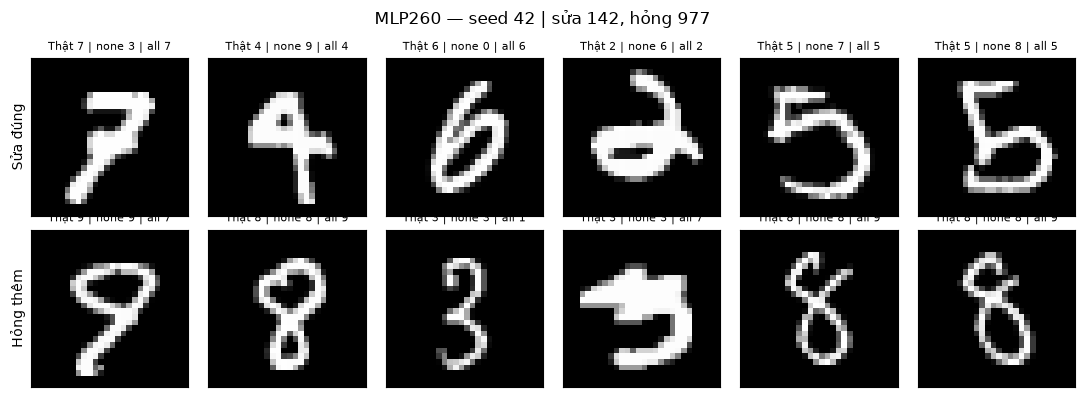

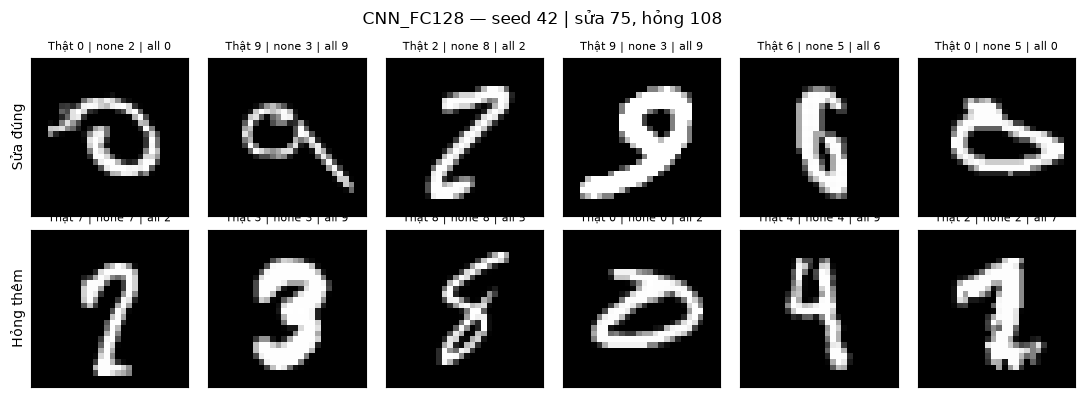

In [6]:
for name in makers:
    p0=predictions[name,'none','Test'];p1=predictions[name,'all','Test']
    fixed=np.flatnonzero((p0!=y_test)&(p1==y_test));broken=np.flatnonzero((p0==y_test)&(p1!=y_test))
    fig,axes=plt.subplots(2,6,figsize=(11,4))
    for row,(indices,title) in enumerate([(fixed,'Sửa đúng'),(broken,'Hỏng thêm')]):
        chosen=np.random.default_rng(SEED).choice(indices,min(6,len(indices)),replace=False)
        for ax in axes[row]:ax.set_xticks([]);ax.set_yticks([])
        for ax,i in zip(axes[row],chosen):
            ax.imshow(X_test[i].reshape(28,28),cmap='gray');ax.set_title(f'Thật {y_test[i]} | none {p0[i]} | all {p1[i]}',fontsize=8)
        axes[row,0].set_ylabel(title)
    fig.suptitle(f'{name} — seed {SEED} | sửa {len(fixed)}, hỏng {len(broken)}')
    fig.tight_layout();fig.savefig(OUTPUT/f'errors_{name}.png',dpi=300);plt.show()

In [7]:
for name,table in dict(metrics=metrics,comparison=comparison,augmentation_effect=effects,
    runs=runs,robustness=robustness).items():table.to_csv(OUTPUT/f'{name}.csv',index=False)
for (name,mode),h in histories.items():h.to_csv(OUTPUT/f'history_{name}_{mode}.csv',index=False)
np.savez_compressed(OUTPUT/'split_indices.npz',train_idx=tr,val_idx=va,seed=SEED)
np.savez_compressed(OUTPUT/'test_predictions.npz',y_true=y_test,
    **{f'{name}_{mode}':p for (name,mode,split),p in predictions.items() if split=='Test'})
config=dict(seed=SEED,epochs=EPOCHS,batch_size=BATCH_SIZE,learning_rate=LR,momentum=MOMENTUM,
    optimizer='SGD',parameters=parameters,checkpoint='minimum clean validation CE',
    augmentation=dict(rotation_degrees=MAX_ROTATION,translation_pixels=MAX_SHIFT,gaussian_std=NOISE_STD,
        pixel_clip=[0,1],train_only=True,shared_between_models=True),
    preprocessing='loader pixel /255; N,1,28,28',
    robustness=dict(split='Test',shifts=SHIFTS,rotations=ROTATIONS,noise=False),
    device=str(DEVICE),torch_version=str(torch.__version__))
(OUTPUT/'config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('Đã lưu:',OUTPUT)

Đã lưu: d:\Nhận dạng mẫu\mnist\results\cnn_mlp_augmentation
